In [7]:
import json

INST_TUNING_CLASSIF_DS = "inst_tuning_analysis/openhermes2_5_sample.csv"
INST_TUNING_CLASSIF_HISTORY = "inst_tuning_analysis/inst_tuning_analysis/history-inst_tuning_analysis.json"
history_file = json.load(open(INST_TUNING_CLASSIF_HISTORY, "r"))


In [9]:
import pandas as pd

public_inst_df = pd.read_csv(INST_TUNING_CLASSIF_DS)[["source", "instruction"]]
public_inst_df

,source,instruction
0,CamelAI,A group of 100 patients were treated for a par...
1,CamelAI,"""How can molecular dynamics simulations be use..."
2,CamelAI,A radioactive element has a half-life of 30 ye...
3,CamelAI,What is the value of Euler's totient function ...
4,CamelAI,A manufacturer wants to produce a composite ma...
...,...,...
1395,platypus,"The complex number $z$ is equal to $9 + bi$, w..."
1396,platypus,"In the diagram, $\triangle XYZ$ is right-angle..."
1397,platypus,"Last year, a woman was able to demonstrate tha..."
1398,platypus,"If $\sqrt{5 + x} + \sqrt{20 - x} = 7$, what is..."


In [23]:
tone_answers = []
for msg in history_file['tone_classification-chatgpt_4o_latest']['messages']:
    answer = msg['chat_history'][1]["content"].lower()
    tone_answers.append(answer)


grammar_answer = []
for msg in history_file['grammar_classification-chatgpt_4o_latest']['messages']:
    answer = msg['chat_history'][1]["content"].lower()
    grammar_answer.append(answer)

public_inst_df['tone'] = tone_answers
public_inst_df['grammaticality'] = grammar_answer

In [24]:
public_inst_df

,source,instruction,tone,grammaticality
0,CamelAI,A group of 100 patients were treated for a par...,declarative,correct
1,CamelAI,"""How can molecular dynamics simulations be use...",interrogative,correct
2,CamelAI,A radioactive element has a half-life of 30 ye...,interrogative,correct
3,CamelAI,What is the value of Euler's totient function ...,interrogative,correct
4,CamelAI,A manufacturer wants to produce a composite ma...,imperative,correct
...,...,...,...,...
1395,platypus,"The complex number $z$ is equal to $9 + bi$, w...",declarative,correct
1396,platypus,"In the diagram, $\triangle XYZ$ is right-angle...",imperative,correct
1397,platypus,"Last year, a woman was able to demonstrate tha...",declarative,correct
1398,platypus,"If $\sqrt{5 + x} + \sqrt{20 - x} = 7$, what is...",interrogative,correct


In [29]:
full_data = {}
for groupname, group in public_inst_df.groupby("source"):
    full_data[groupname] = {
        "tone" : group['tone'].value_counts().to_dict(),
        "grammaticality" : group['grammaticality'].value_counts().to_dict(),
    }


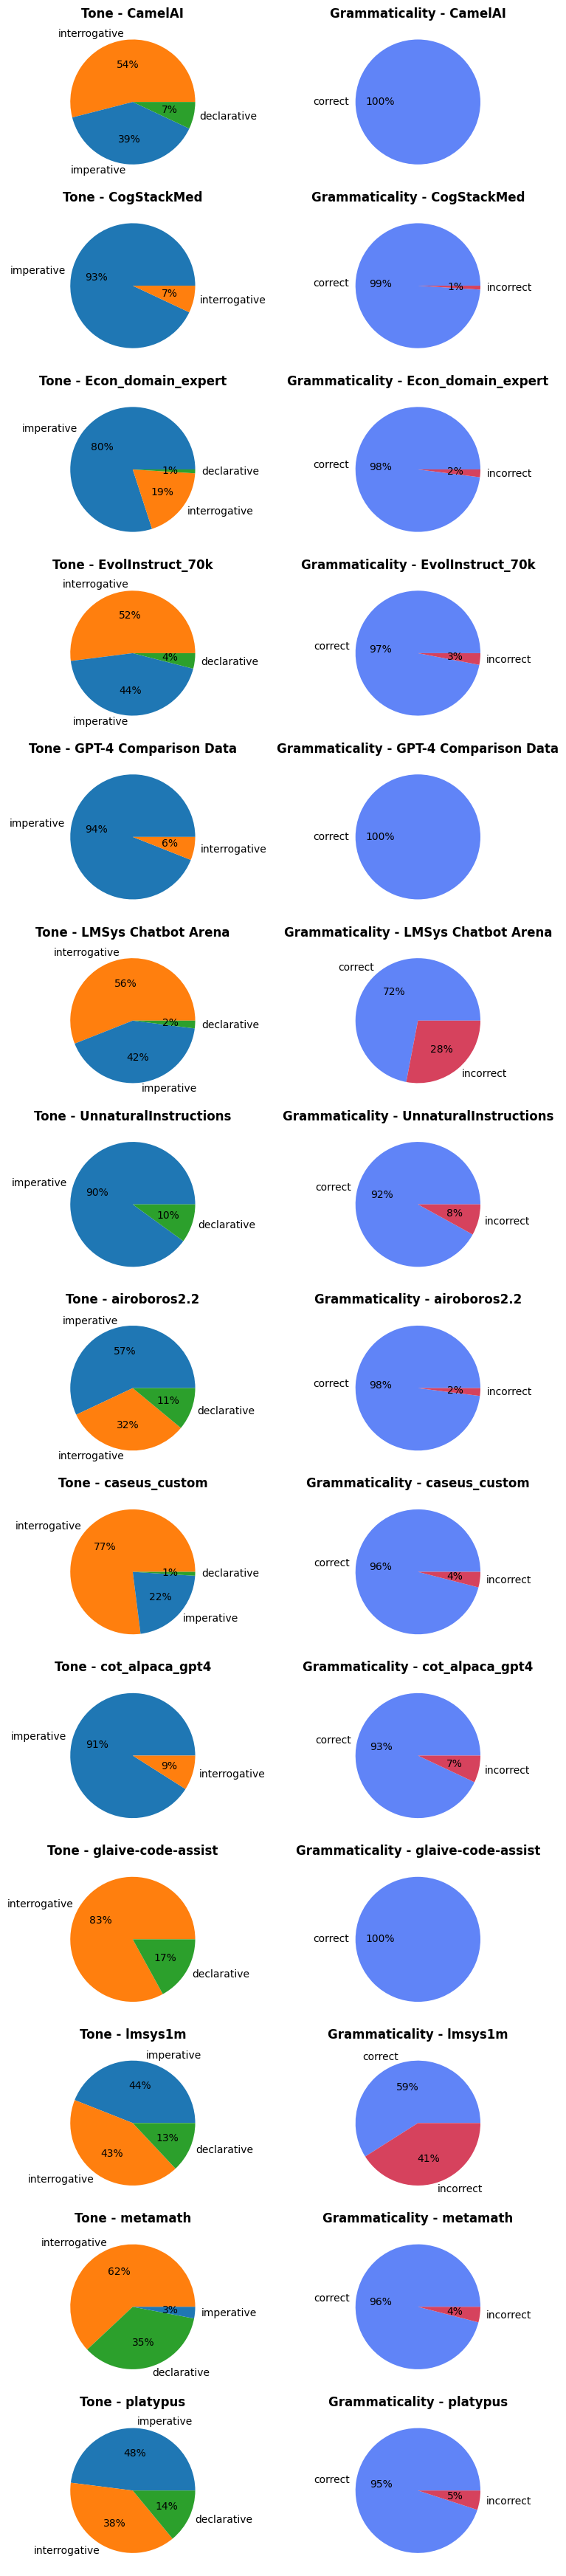

In [41]:
color_dict = {
    "imperative" : "#1f77b4",
    "interrogative" : "#ff7f0e",
    "declarative" : "#2ca02c",
    "correct" : "#6084f7",
    "incorrect" : "#d6425d",
}

#  Sort keys to make consistent grid layout
keys = sorted(full_data.keys())
n = len(keys)

fig, axes = plt.subplots(nrows=n, ncols=2, figsize=(8, n * 2.5))

for i, key in enumerate(keys):
    d = full_data[key]
    # Tones (left column)
    tone_ax = axes[i][0]
    tone_data = d['tone']
    tone_labels = list(tone_data.keys())
    tone_values = list(tone_data.values())
    tone_colors_used = [color_dict[label] for label in tone_labels]
    tone_ax.pie(tone_data.values(), labels=tone_data.keys(), autopct='%1.0f%%', colors=tone_colors_used)
    tone_ax.set_title(f'Tone - {key}', fontweight="bold")

    # Grammar (right column)
    grammar_ax = axes[i][1]
    grammar_data = d['grammaticality']
    grammar_labels = list(grammar_data.keys())
    grammar_values = list(grammar_data.values())
    grammar_colors_used = [color_dict[label] for label in grammar_labels]
    grammar_ax.pie(grammar_data.values(), labels=grammar_data.keys(), autopct='%1.0f%%', colors=grammar_colors_used)
    grammar_ax.set_title(f'Grammaticality - {key}', fontweight="bold")

plt.tight_layout()
plt.show()

In [26]:
group

,source,instruction,tone,grammaticality
1300,platypus,"Let $\mathbf{m},$ $\mathbf{n},$ and $\mathbf{p...",imperative,correct
1301,platypus,Which text uses the word travesty in its tradi...,interrogative,correct
1302,platypus,Certain politicians in the country of Birangi ...,imperative,correct
1303,platypus,Implement a Golang function that accepts a str...,imperative,correct
1304,platypus,What is $123_{10}$ when expressed in base $5$?,interrogative,correct
...,...,...,...,...
1395,platypus,"The complex number $z$ is equal to $9 + bi$, w...",declarative,correct
1396,platypus,"In the diagram, $\triangle XYZ$ is right-angle...",imperative,correct
1397,platypus,"Last year, a woman was able to demonstrate tha...",declarative,correct
1398,platypus,"If $\sqrt{5 + x} + \sqrt{20 - x} = 7$, what is...",interrogative,correct


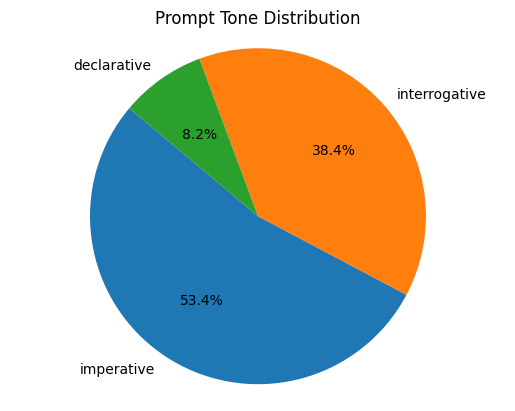

In [ ]:
import matplotlib.pyplot as plt
# ['tone_classification-chatgpt_4o_latest', 'grammar_classification-chatgpt_4o_latest']
# tone_classif
tone_ft = {
    "imperative" : 0,
    "interrogative" : 0,
    "declarative" : 0,
}


for msg in history_file['tone_classification-chatgpt_4o_latest']['messages']:
    answer = msg['chat_history'][1]["content"].lower()
    if "imperative" in answer:
        tone_ft["imperative"] += 1
    elif "interrogative" in answer:
        tone_ft["interrogative"] += 1
    elif "declarative" in answer:
        tone_ft["declarative"] += 1
    else:
        print("hayo gaada")

plt.pie(tone_ft.values(), labels=tone_ft.keys(), autopct='%1.1f%%', startangle=140)
plt.title('Prompt Tone Distribution')
plt.axis('equal')
plt.show()

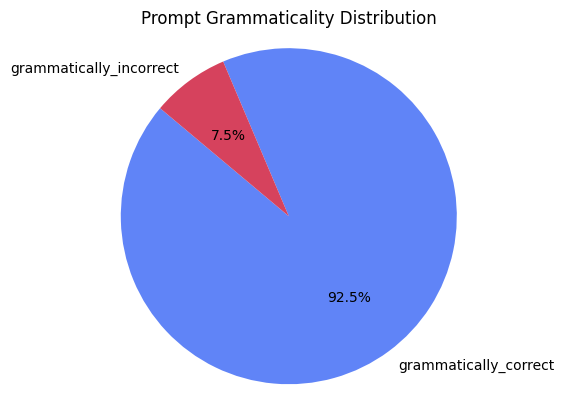

In [11]:
# ['tone_classification-chatgpt_4o_latest', 'grammar_classification-chatgpt_4o_latest']
# tone_classif

colors = {
    "correct" : '#6084f7',
    "incorrect" : '#d6425d',
}
tone_ft = {
    "grammatically_correct" : 0,
    "grammatically_incorrect" : 0,
}
for msg in history_file['grammar_classification-chatgpt_4o_latest']['messages']:
    answer = msg['chat_history'][1]["content"].lower()
    if answer == "correct":
        tone_ft["grammatically_correct"] += 1
    elif answer == "incorrect":
        tone_ft["grammatically_incorrect"] += 1
    else:
        print("hayo gaada")

plt.pie(tone_ft.values(), labels=tone_ft.keys(), autopct='%1.1f%%', startangle=140, colors=colors.values())
plt.title('Prompt Grammaticality Distribution')
plt.axis('equal')
plt.show()